# Team attacking profiles

## tl;dr

Compare **shot volume, chance quality and attacking patterns** using the original frozen
`stack_identity` predictions. The data covers **6,868 non-penalty shots, 273 matches and 98 teams**
from April 11 to May 17, 2016. This is a late-season test window, **not a full-season ranking**.

The examples compare Tottenham Hotspur and Chelsea against Premier League peers. Change the
league and teams in the selector, or use the plotting functions directly. The notebook includes
coverage checks, a team table, volume-versus-quality and attack-versus-defence plots, shot-pattern
profiles, pitch maps and match-by-match trends. No training or model inference is required.

## Context and methods

### Key assumptions

- **npxG** is the sum of the frozen goal probabilities for non-penalty shots. Own goals and penalty goals
  are not included in the non-penalty shot-goal counts.
- Count **both teams in every covered match**, including a team with zero non-penalty shots. Per-match
  values use these appearances, not the count of matches where a team happened to shoot.
- **Shot quality** is total npxG divided by total shots. A team with no shots has unavailable shot quality,
  not zero quality. League references are computed from pooled numerators and denominators.
- Against-values come from the opponent in the **same match**, using verified fixture team IDs.
- Comparisons are within leagues and are not adjusted for opponent strength, game state or schedule.
  Four to seven matches per team give a descriptive profile, not a stable estimate of team ability.
- Shot-pattern indicators can overlap. For example, a shot can be headed, pressured and cross-assisted.
  Their shares must not be added together. These describe shots taken, not all attacking possessions.
- Coordinates and distances use the project's 120-by-80 pitch. All teams attack right in the pitch maps.

A **CPU Colab Python kernel is sufficient**. The notebook reads saved artifacts independently of the
training notebook and does not modify them.

### 1. Imports and paths

Required packages are `numpy`, `pandas`, `pyarrow`, `matplotlib`, `requests` and IPython.
`ipywidgets` is optional for the live selector. Install missing packages in the selected kernel:

```python
%pip install numpy pandas pyarrow matplotlib requests ipywidgets
```

Update `ARTIFACT_ROOT` or set `CONTEXTUAL_XG_ARTIFACT_ROOT` for a local copy of the original
Drive project. Public match catalogues are cached once per pinned commit; individual event files
are unnecessary for this analysis.

In [1]:
import hashlib
import html
import json
import os
import tempfile
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Arc, Circle, Rectangle
import numpy as np
import pandas as pd
import requests
from IPython import get_ipython
from IPython.display import Markdown, display

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib","inline")
plt.rcParams.update({
    "figure.dpi":120,"savefig.dpi":180,"font.size":10,
    "axes.spines.top":False,"axes.spines.right":False,
    "axes.facecolor":"white","figure.facecolor":"white",
    "text.color":"#172033","axes.labelcolor":"#334155",
})
COMMIT="3bfbffe1de5750ebd47d770be0bb924a10cde54f"
ARTIFACT_ROOT=Path(os.environ.get("CONTEXTUAL_XG_ARTIFACT_ROOT","/content/drive/MyDrive/xg-python")).expanduser()
CACHE_DIR=Path(os.environ.get("CONTEXTUAL_XG_MATCH_CACHE",str(Path(tempfile.gettempdir())/"contextual-xg-match-analysis")))/COMMIT
DEFAULT_LEAGUE="Premier League"
DEFAULT_TEAMS=("Tottenham Hotspur","Chelsea")
TEAM_COLORS=["#2563eb","#b45309"]
if str(ARTIFACT_ROOT).startswith("/content/drive/") and not Path("/content/drive/MyDrive").is_dir():
    from google.colab import drive
    drive.mount("/content/drive")
CACHE_DIR.mkdir(parents=True,exist_ok=True)
FINAL_RELATIVE=Path("models")/COMMIT/"final_evaluation"
FEATURE_RELATIVE=(Path("data/processed")/COMMIT/"features_stage_08.parquet").as_posix()

Mounted at /content/drive


## Data

### 2. Read and verify the original predictions and features

Files are checked against the frozen hashes before use. Predictions are joined one-to-one by `shot_id`;
match and split routing must agree. StatsBomb's benchmark is retained as a labeled comparator and is
never substituted for the project model.

In [2]:
def sha256_file(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream,"sha256").hexdigest()

def require_file(relative,expected_hash=None):
    path=ARTIFACT_ROOT/relative
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. Mount Drive or update ARTIFACT_ROOT to the original project.")
    if expected_hash is not None and sha256_file(path)!=expected_hash:
        raise ValueError(f"Frozen artifact hash mismatch: {relative}")
    return path

result=json.loads(require_file(FINAL_RELATIVE/"test_result.json").read_text())
manifest=json.loads(require_file(FINAL_RELATIVE/"frozen_manifest.json",result["frozen_manifest_sha256"]).read_text())
if (manifest["data_source"]!={"repository":"hudl/open-data","commit":COMMIT}
        or manifest["selected_model"]!="stack_identity" or manifest["calibration"]["method"]!="identity"):
    raise ValueError("Expected the original pinned stack with identity calibration.")
prediction_relative=result["artifacts"]["test_model_predictions.parquet"]
prediction_path=require_file(prediction_relative,result["artifact_sha256"][prediction_relative])
feature_path=require_file(FEATURE_RELATIVE,manifest["files"][FEATURE_RELATIVE]["sha256"])
matches_path=require_file("matches.parquet",manifest["files"]["matches.parquet"]["sha256"])
predictions=pd.read_parquet(prediction_path,columns=["shot_id","match_id","split","stack_identity"])
features=pd.read_parquet(feature_path,filters=[("split","==","test")])
all_matches=pd.read_parquet(matches_path)
for frame in [predictions,features]:
    if frame.shot_id.isna().any() or not frame.shot_id.is_unique or not frame.split.eq("test").all():
        raise ValueError("Invalid test IDs or split labels.")
if len(predictions)!=manifest["evaluation_protocol"]["expected_test_shots"] or set(predictions.shot_id)!=set(features.shot_id):
    raise ValueError("Feature and prediction coverage differ.")
if not predictions.shot_id.map(features.set_index("shot_id").match_id).eq(predictions.match_id).all():
    raise ValueError("Shot-to-match routing differs between features and predictions.")
shots=features.merge(predictions[["shot_id","stack_identity"]],on="shot_id",validate="one_to_one")
probabilities=shots[["stack_identity","benchmark_statsbomb_xg"]].to_numpy(dtype=float)
if not np.isfinite(probabilities).all() or ((probabilities<0)|(probabilities>1)).any():
    raise ValueError("Missing or invalid model or benchmark probabilities.")
if shots.is_goal.isna().any() or not shots.shot_type.ne("Penalty").all():
    raise ValueError("Invalid target or non-penalty eligibility.")
if not all_matches.match_id.is_unique:
    raise ValueError("Duplicate saved match metadata.")
covered_matches=all_matches.loc[all_matches.split.eq("test")].copy()
if (len(covered_matches)!=manifest["evaluation_protocol"]["expected_test_matches"]
        or set(covered_matches.match_id)!=set(shots.match_id)):
    raise ValueError("The saved test fixture set is incomplete.")
SCOPE_START=pd.to_datetime(covered_matches.match_date).min()
SCOPE_END=pd.to_datetime(covered_matches.match_date).max()
SCOPE_LABEL=f"{SCOPE_START:%d %b} to {SCOPE_END:%d %b %Y}"
print(f"Verified {len(shots):,} non-penalty shots in {len(covered_matches)} matches; {SCOPE_LABEL}.")


Verified 6,868 non-penalty shots in 273 matches; 11 Apr to 17 May 2016.


### 3. Resolve home and away team IDs from pinned fixture catalogues

The saved match table has names but no team IDs. Read the five public season catalogues to obtain
explicit home/away IDs. Dates, names and competitions must agree with the saved metadata.
No team identity is inferred from shot counts or from the order of events.

In [3]:
public_records=[]
catalogue_sources=[]
competition_seasons=covered_matches[["competition_id","season_id"]].drop_duplicates()
for competition,season in competition_seasons.itertuples(index=False,name=None):
    cache=CACHE_DIR/f"matches-{int(competition)}-{int(season)}.json"
    url=f"https://raw.githubusercontent.com/hudl/open-data/{COMMIT}/data/matches/{int(competition)}/{int(season)}.json"
    if cache.is_file():
        rows=json.loads(cache.read_text())
    else:
        response=requests.get(url,timeout=(15,60));response.raise_for_status();rows=response.json()
        temporary=cache.with_name(cache.name+".part")
        try:
            temporary.write_text(json.dumps(rows,separators=(",",":")),encoding="utf-8")
            temporary.replace(cache)
        finally:
            temporary.unlink(missing_ok=True)
    catalogue_sources.append({"url":url,"sha256_of_cached_json":sha256_file(cache)})
    for row in rows:
        public_records.append({
            "match_id":row["match_id"],"home_team_id":row["home_team"]["home_team_id"],
            "away_team_id":row["away_team"]["away_team_id"],
            "public_home":row["home_team"]["home_team_name"],"public_away":row["away_team"]["away_team_name"],
            "public_date":row["match_date"],"public_competition":row["competition"]["competition_id"],
        })
public_fixtures=pd.DataFrame(public_records)
if not public_fixtures.match_id.is_unique:
    raise ValueError("Duplicate IDs across pinned fixture catalogues.")
fixtures=covered_matches.merge(public_fixtures,on="match_id",how="left",validate="one_to_one")
if (fixtures[["home_team_id","away_team_id"]].isna().any().any()
        or not fixtures.home_team.eq(fixtures.public_home).all()
        or not fixtures.away_team.eq(fixtures.public_away).all()
        or not pd.to_datetime(fixtures.match_date).eq(pd.to_datetime(fixtures.public_date)).all()
        or not fixtures.competition_id.eq(fixtures.public_competition).all()):
    raise ValueError("Pinned fixture IDs, names, dates or competitions disagree with saved metadata.")
fixtures["match_date"]=pd.to_datetime(fixtures.match_date)
fixtures[["home_team_id","away_team_id"]]=fixtures[["home_team_id","away_team_id"]].astype(int)
fixture_lookup=fixtures.set_index("match_id")
if (not shots.league.eq(shots.match_id.map(fixture_lookup.league)).all()
        or not shots.competition_id.eq(shots.match_id.map(fixture_lookup.competition_id)).all()
        or not pd.to_datetime(shots.match_date).eq(shots.match_id.map(fixture_lookup.match_date)).all()):
    raise ValueError("Shot league, competition or date routing disagrees with its fixture.")
print(f"Resolved both teams in {len(fixtures)} covered fixtures using {len(catalogue_sources)} pinned catalogues.")


Resolved both teams in 273 covered fixtures using 5 pinned catalogues.


### 4. Build a two-sided team-match table

Create a row for each side before joining shots. Fill a missing shot aggregate with zero only when
that covered team appearance has no eligible shots. Missing measurements inside feature rows are
not imputed. Join opponent totals using `match_id` and `opponent_id`.

In [4]:
def fixture_sides(fixture_rows):
    common=["match_id","match_date","competition_id","league"]
    home=fixture_rows[common+["home_team_id","home_team","away_team_id","away_team"]].rename(columns={
        "home_team_id":"team_id","home_team":"team_name","away_team_id":"opponent_id","away_team":"opponent_name"})
    away=fixture_rows[common+["away_team_id","away_team","home_team_id","home_team"]].rename(columns={
        "away_team_id":"team_id","away_team":"team_name","home_team_id":"opponent_id","home_team":"opponent_name"})
    sides=pd.concat([home.assign(venue="Home"),away.assign(venue="Away")],ignore_index=True)
    if (sides.duplicated(["match_id","team_id"]).any()
            or sides.groupby("match_id").size().ne(2).any() or sides.team_id.eq(sides.opponent_id).any()):
        raise ValueError("Each fixture must have exactly two distinct team appearances.")
    identities=sides.groupby("team_id")[["team_name","league"]].nunique()
    if identities.gt(1).any().any():
        raise ValueError("A team ID maps to conflicting names or leagues.")
    return sides


def build_team_games(shot_rows,fixture_rows):
    sides=fixture_sides(fixture_rows)
    if shot_rows.shot_id.isna().any() or not shot_rows.shot_id.is_unique:
        raise ValueError("Shot IDs must be unique and non-missing.")
    routed=shot_rows[["shot_id","match_id","team_id"]].merge(
        sides[["match_id","team_id"]],on=["match_id","team_id"],how="left",indicator=True,validate="many_to_one")
    if not routed["_merge"].eq("both").all():
        raise ValueError("A shooting team is absent from its fixture.")
    required=["stack_identity","benchmark_statsbomb_xg","is_goal"]
    if shot_rows[required].isna().any().any():
        raise ValueError("Missing probability or outcome values must not become zero totals.")
    totals=shot_rows.groupby(["match_id","team_id"]).agg(
        shots_for=("shot_id","size"),goals_for=("is_goal","sum"),
        npxg_for=("stack_identity","sum"),benchmark_for=("benchmark_statsbomb_xg","sum"),
    ).reset_index()
    games=sides.merge(totals,on=["match_id","team_id"],how="left",validate="one_to_one")
    zero_shots=games.shots_for.isna()
    total_cols=["shots_for","goals_for","npxg_for","benchmark_for"]
    games.loc[zero_shots,total_cols]=0
    if games[total_cols].isna().any().any():raise ValueError("Unexpected missing team totals.")
    games[["shots_for","goals_for"]]=games[["shots_for","goals_for"]].astype(int)
    opponents=games[["match_id","team_id",*total_cols]].rename(columns={
        "team_id":"opponent_id","shots_for":"shots_against","goals_for":"goals_against",
        "npxg_for":"npxg_against","benchmark_for":"benchmark_against"})
    games=games.merge(opponents,on=["match_id","opponent_id"],how="left",validate="one_to_one")
    if games[["shots_against","goals_against","npxg_against"]].isna().any().any():
        raise ValueError("An opponent's same-match totals could not be found.")
    return games.sort_values(["match_date","match_id","team_id"]).reset_index(drop=True)


def aggregate_profiles(games):
    profiles=games.groupby(["league","team_id","team_name"]).agg(
        matches=("match_id","size"),first_match=("match_date","min"),last_match=("match_date","max"),
        shots_for=("shots_for","sum"),shots_against=("shots_against","sum"),
        goals_for=("goals_for","sum"),goals_against=("goals_against","sum"),
        npxg_for=("npxg_for","sum"),npxg_against=("npxg_against","sum"),benchmark_for=("benchmark_for","sum"),
    ).reset_index()
    for name in ["shots_for","shots_against","goals_for","goals_against","npxg_for","npxg_against","benchmark_for"]:
        profiles[name+"_per_match"]=profiles[name]/profiles.matches
    profiles["npxg_per_shot"]=profiles.npxg_for/profiles.shots_for.where(profiles.shots_for.gt(0))
    profiles["npxg_difference_per_match"]=(profiles.npxg_for-profiles.npxg_against)/profiles.matches
    profiles["goals_minus_npxg_per_match"]=(profiles.goals_for-profiles.npxg_for)/profiles.matches
    return profiles

team_games=build_team_games(shots,fixtures)
profiles=aggregate_profiles(team_games)
sides=fixture_sides(fixtures)
shots=shots.merge(sides[["match_id","team_id","team_name","opponent_name"]],
                  on=["match_id","team_id"],how="left",validate="many_to_one")
if shots.team_name.isna().any():raise ValueError("A shot is missing its verified team name.")
coverage=profiles.groupby("league").agg(teams=("team_id","size"),appearances=("matches","sum"),
    minimum_matches=("matches","min"),maximum_matches=("matches","max"),
    shots=("shots_for","sum"),first_match=("first_match","min"),last_match=("last_match","max"))
coverage["fixtures"]=coverage.appearances//2
print(f"Built {len(team_games)} team appearances and {len(profiles)} team profiles.")
display(coverage[["teams","fixtures","minimum_matches","maximum_matches","shots","first_match","last_match"]])


Built 546 team appearances and 98 team profiles.


,teams,fixtures,minimum_matches,maximum_matches,shots,first_match,last_match
league,,,,,,,
1. Bundesliga,18,45,5,5,1113,2016-04-15,2016-05-14
La Liga,20,61,6,7,1419,2016-04-11,2016-05-15
Ligue 1,20,49,4,5,1165,2016-04-15,2016-05-14
Premier League,20,57,5,7,1551,2016-04-13,2016-05-17
Serie A,20,61,6,7,1620,2016-04-11,2016-05-15


## Results

### 5. League table and pooled reference values

The table is ordered by model npxG created per match and shows the actual match count. The full
`profile_table(league)` result also includes exposure dates and the StatsBomb comparator. The comparator
is a second model's estimate of the same shots, not an accuracy ranking.
The two selected teams are highlighted in the plots; other league teams form the peer distribution.

In [5]:
def league_profiles(league):
    rows=profiles.loc[profiles.league.eq(league)].copy()
    if rows.empty:raise ValueError("Choose a league in the covered fixture set.")
    return rows


def league_reference(league):
    rows=league_profiles(league)
    return {
        "shots_per_match":rows.shots_for.sum()/rows.matches.sum(),
        "npxg_per_match":rows.npxg_for.sum()/rows.matches.sum(),
        "npxg_per_shot":rows.npxg_for.sum()/rows.shots_for.sum() if rows.shots_for.sum()>0 else np.nan,
    }


def selected_profiles(league,teams):
    if not teams or len(teams)>2 or len(set(teams))!=len(teams):
        raise ValueError("Choose one or two distinct teams.")
    rows=league_profiles(league).set_index("team_name")
    if not set(teams).issubset(rows.index):raise ValueError("All selected teams must belong to the chosen league.")
    return rows.loc[list(teams)]


def round_numeric(table):
    return table.round({column:3 for column in table.select_dtypes(include="number").columns})


def profile_table(league):
    columns=["team_name","matches","shots_for_per_match","npxg_per_shot","npxg_for_per_match",
             "npxg_against_per_match","npxg_difference_per_match","goals_minus_npxg_per_match",
             "benchmark_for_per_match","first_match","last_match"]
    table=league_profiles(league).sort_values(["npxg_for_per_match","team_name"],ascending=[False,True])[columns].reset_index(drop=True)
    table.index+=1
    return round_numeric(table.rename(columns={
        "team_name":"Team","matches":"Matches","shots_for_per_match":"Shots / match",
        "npxg_per_shot":"npxG / shot","npxg_for_per_match":"npxG for / match",
        "npxg_against_per_match":"npxG against / match","npxg_difference_per_match":"npxG diff / match",
        "goals_minus_npxg_per_match":"(NP goals − npxG) / match","benchmark_for_per_match":"StatsBomb npxG / match",
        "first_match":"First match","last_match":"Last match",
    }))

PROFILE_COLUMNS=["Team","Matches","Shots / match","npxG / shot","npxG for / match", "npxG against / match","npxG diff / match"]
display(profile_table(DEFAULT_LEAGUE)[PROFILE_COLUMNS])
reference=league_reference(DEFAULT_LEAGUE)
display(Markdown(f"**{DEFAULT_LEAGUE} pooled reference:** {reference['shots_per_match']:.2f} shots per team appearance, "
                 f"{reference['npxg_per_shot']:.3f} npxG per shot and {reference['npxg_per_match']:.2f} npxG per team appearance. "
                 f"Coverage: **{SCOPE_LABEL}**."))


,Team,Matches,Shots / match,npxG / shot,npxG for / match,npxG against / match,npxG diff / match
1,Southampton,5,16.000,0.132,2.108,1.134,0.974
2,West Ham United,6,18.500,0.110,2.035,1.176,0.859
3,Tottenham Hotspur,5,18.200,0.108,1.966,0.922,1.045
4,Liverpool,7,19.000,0.102,1.931,1.150,0.781
5,Leicester City,5,17.400,0.106,1.846,1.101,0.745
6,Arsenal,6,15.500,0.105,1.629,0.569,1.060
7,Manchester City,6,11.500,0.119,1.368,1.175,0.194
8,Manchester United,6,13.500,0.098,1.327,0.890,0.438
9,Swansea City,5,11.600,0.114,1.321,2.023,-0.702
10,Norwich City,5,13.800,0.092,1.275,1.286,-0.010


**Premier League pooled reference:** 13.61 shots per team appearance, 0.097 npxG per shot and 1.32 npxG per team appearance. Coverage: **11 Apr to 17 May 2016**.

### 6. Shot volume versus chance quality

Horizontal position shows shots per match; vertical position shows npxG per shot. Circle area is
proportional to npxG created per match. Pooled league reference lines divide the plot into relative
volume and quality profiles. Other league teams are shown in grey; their identities and values are
available in the league table. A higher value is not evidence of a specific tactical cause.

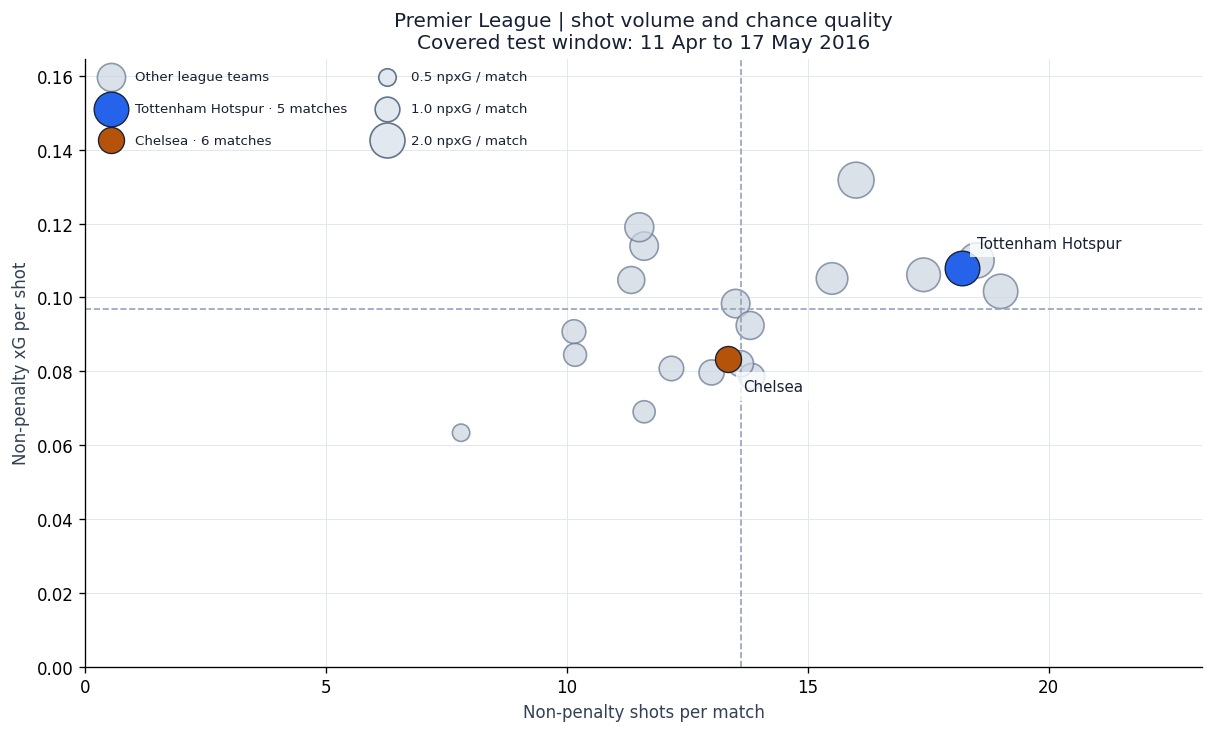

In [6]:
def plot_volume_quality(league,teams):
    peers=league_profiles(league)
    selected=selected_profiles(league,teams)
    reference=league_reference(league)
    background=peers.loc[~peers.team_name.isin(teams)].dropna(subset=["npxg_per_shot"])
    fig,ax=plt.subplots(figsize=(10,6),layout="constrained")
    ax.scatter(background.shots_for_per_match,background.npxg_per_shot,
               s=220*background.npxg_for_per_match,color="#cbd5e1",ec="#64748b",alpha=.7,label="Other league teams")
    for i,(team,row) in enumerate(selected.iterrows()):
        if pd.isna(row.npxg_per_shot):continue
        ax.scatter(row.shots_for_per_match,row.npxg_per_shot,s=220*row.npxg_for_per_match,
                   color=TEAM_COLORS[i],ec="#172033",lw=.8,zorder=3,label=f"{team} · {int(row.matches)} matches")
        ax.annotate(team,(row.shots_for_per_match,row.npxg_per_shot),xytext=(9,12 if i==0 else -19),
                    textcoords="offset points",fontsize=9,bbox={"facecolor":"white","alpha":.8,"edgecolor":"none"})
    ax.axvline(reference["shots_per_match"],color="#94a3b8",ls="--",lw=1)
    ax.axhline(reference["npxg_per_shot"],color="#94a3b8",ls="--",lw=1)
    for size in [.5,1.,2.]:
        ax.scatter([],[],s=220*size,color="#e2e8f0",ec="#64748b",label=f"{size:.1f} npxG / match")
    ax.set(xlabel="Non-penalty shots per match",ylabel="Non-penalty xG per shot",
           xlim=(0,peers.shots_for_per_match.max()*1.22),ylim=(0,peers.npxg_per_shot.max()*1.25),
           title=f"{league} | shot volume and chance quality\nCovered test window: {SCOPE_LABEL}")
    ax.legend(loc="upper left",frameon=False,fontsize=8,ncol=2,labelspacing=1.4)
    ax.grid(color="#e2e8f0",lw=.6);ax.set_axisbelow(True)
    plt.show();plt.close(fig)
    return fig

volume_figure=plot_volume_quality(DEFAULT_LEAGUE,DEFAULT_TEAMS)


### 7. Attacking output and chances conceded

The upper-left region combines higher attacking npxG with lower opponent npxG. The equality line
marks balanced for/against values. This is a team-level comparison, not a goalkeeper shot-stopping
rating. Both axes use the same units and scale.

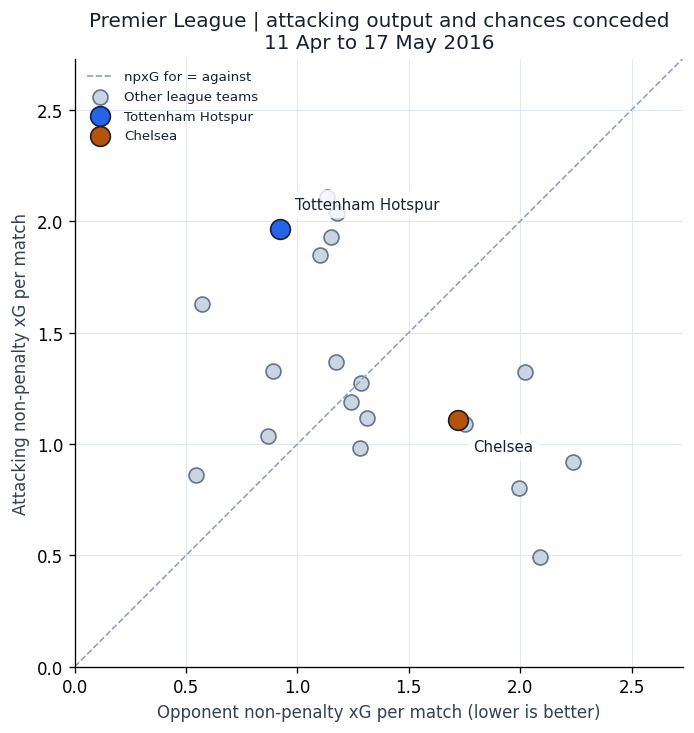

In [7]:
def plot_attack_defence(league,teams):
    peers=league_profiles(league)
    selected=selected_profiles(league,teams)
    background=peers.loc[~peers.team_name.isin(teams)]
    maximum=peers[["npxg_for_per_match","npxg_against_per_match"]].to_numpy().max()*1.22
    fig,ax=plt.subplots(figsize=(8.8,6),layout="constrained")
    ax.plot([0,maximum],[0,maximum],ls="--",lw=1,color="#94a3b8",label="npxG for = against")
    ax.scatter(background.npxg_against_per_match,background.npxg_for_per_match,
               s=80,color="#cbd5e1",ec="#64748b",label="Other league teams")
    for i,(team,row) in enumerate(selected.iterrows()):
        ax.scatter(row.npxg_against_per_match,row.npxg_for_per_match,s=140,
                   color=TEAM_COLORS[i],ec="#172033",zorder=3,label=team)
        ax.annotate(team,(row.npxg_against_per_match,row.npxg_for_per_match),xytext=(9,12 if i==0 else -19),
                    textcoords="offset points",fontsize=9,bbox={"facecolor":"white","alpha":.8,"edgecolor":"none"})
    ax.set(xlim=(0,maximum),ylim=(0,maximum),aspect="equal",xlabel="Opponent non-penalty xG per match (lower is better)",
           ylabel="Attacking non-penalty xG per match",title=f"{league} | attacking output and chances conceded\n{SCOPE_LABEL}")
    ax.legend(loc="upper left",frameon=False,fontsize=8)
    ax.grid(color="#e2e8f0",lw=.6);ax.set_axisbelow(True)
    plt.show();plt.close(fig)
    return fig

balance_figure=plot_attack_defence(DEFAULT_LEAGUE,DEFAULT_TEAMS)


### 8. Shot-pattern profiles

Compare the share of shots with each observed characteristic. Crosses, cutbacks and through balls
refer to the explicitly linked assisting pass. Prior carries refer to earlier events in the same
possession. Categories overlap and describe the shots that occurred; they do not measure the success
rate of all crosses, passes or carries, and they do not establish causal tactical effects.
A zero share means observed absence. Mean xG is unavailable when a pattern has no matching shots.

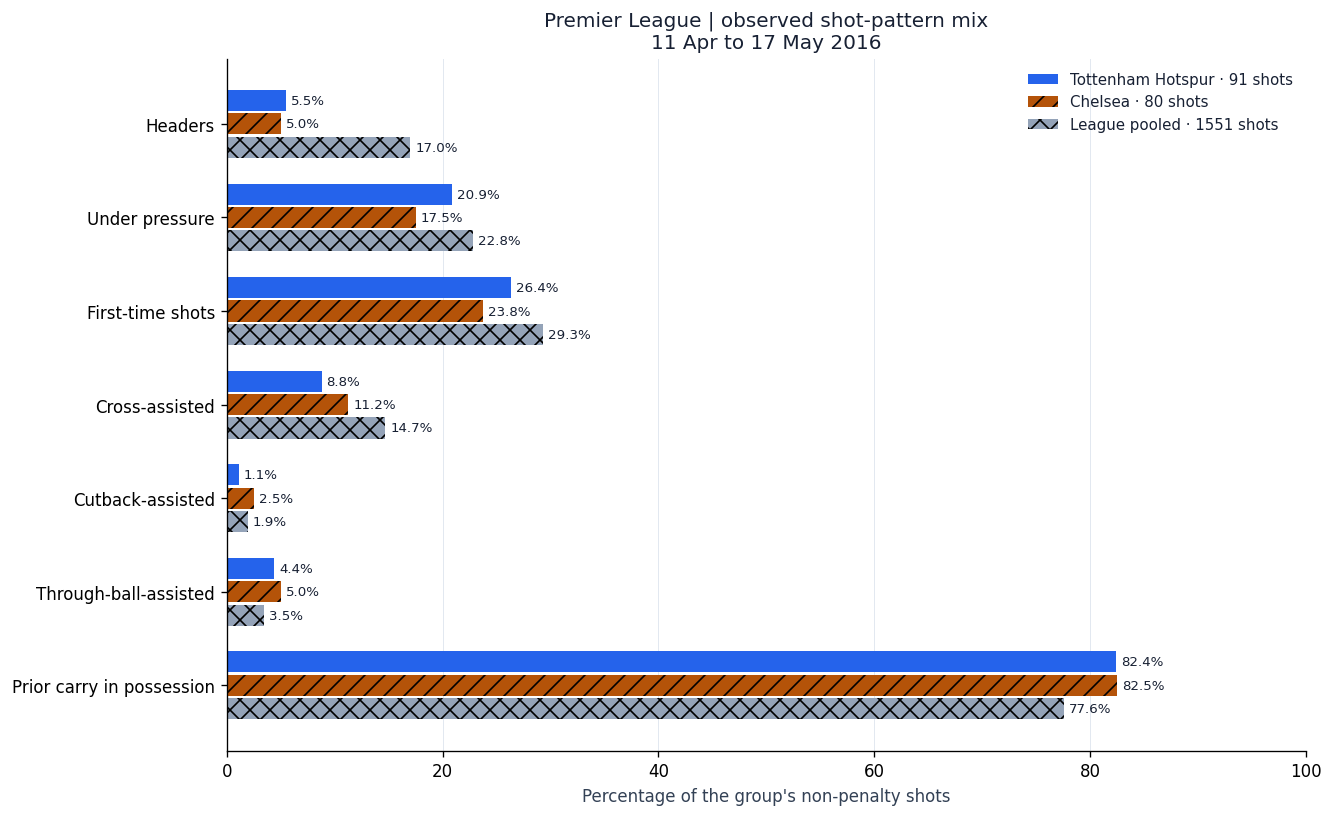

,group,pattern,shots_in_pattern,total_shots,share,mean_xg
0,Tottenham Hotspur,Headers,5,91,0.055,0.122
1,Tottenham Hotspur,Under pressure,19,91,0.209,0.236
2,Tottenham Hotspur,First-time shots,24,91,0.264,0.119
3,Tottenham Hotspur,Cross-assisted,8,91,0.088,0.120
4,Tottenham Hotspur,Cutback-assisted,1,91,0.011,0.024
5,Tottenham Hotspur,Through-ball-assisted,4,91,0.044,0.487
6,Tottenham Hotspur,Prior carry in possession,75,91,0.824,0.111
7,Chelsea,Headers,4,80,0.050,0.087
8,Chelsea,Under pressure,14,80,0.175,0.074
9,Chelsea,First-time shots,19,80,0.238,0.109


In [8]:
PATTERN_ORDER=["Headers","Under pressure","First-time shots","Cross-assisted", "Cutback-assisted","Through-ball-assisted","Prior carry in possession"]

def pattern_indicators(rows):
    required=["body_part","under_pressure","first_time","pass_cross","pass_cut_back", "pass_through_ball","possession_carries_before_shot"]
    if rows[required].isna().any().any():raise ValueError("Missing pattern inputs must not be treated as absent.")
    return pd.DataFrame({
        "Headers":rows.body_part.eq("Head"),"Under pressure":rows.under_pressure.eq(True),
        "First-time shots":rows.first_time.eq(True),"Cross-assisted":rows.pass_cross.eq(True),
        "Cutback-assisted":rows.pass_cut_back.eq(True),"Through-ball-assisted":rows.pass_through_ball.eq(True),
        "Prior carry in possession":rows.possession_carries_before_shot.gt(0),
    },index=rows.index)


def pattern_summary(league,teams):
    selected_profiles(league,teams)
    cohort=shots.loc[shots.league.eq(league)]
    records=[]
    for label,rows in [(team,cohort.loc[cohort.team_name.eq(team)]) for team in teams]+[("League pooled",cohort)]:
        indicators=pattern_indicators(rows)
        for pattern in PATTERN_ORDER:
            count=int(indicators[pattern].sum())
            records.append({"group":label,"pattern":pattern,"shots_in_pattern":count,"total_shots":len(rows),
                            "share":count/len(rows) if len(rows) else np.nan,
                            "mean_xg":rows.loc[indicators[pattern],"stack_identity"].mean() if count else np.nan})
    return pd.DataFrame(records)


def plot_patterns(league,teams):
    table=pattern_summary(league,teams)
    groups=[*teams,"League pooled"]
    fig,ax=plt.subplots(figsize=(11,6.7),layout="constrained")
    width=.75/len(groups)
    for i,group in enumerate(groups):
        values=table.loc[table.group.eq(group)].set_index("pattern").loc[PATTERN_ORDER]
        offsets=np.arange(len(PATTERN_ORDER))+(i-(len(groups)-1)/2)*width
        color=TEAM_COLORS[i] if group!="League pooled" else "#94a3b8"
        bars=ax.barh(offsets,100*values.share,height=width*.9,color=color,
                     hatch="" if i==0 else ("//" if i==1 else "xx"),label=f"{group} · {int(values.total_shots.iloc[0])} shots")
        ax.bar_label(bars,labels=[f"{100*v:.1f}%" if pd.notna(v) else "n/a" for v in values.share],padding=3,fontsize=8)
    ax.set(yticks=np.arange(len(PATTERN_ORDER)),yticklabels=PATTERN_ORDER,xlim=(0,100),
           xlabel="Percentage of the group's non-penalty shots",title=f"{league} | observed shot-pattern mix\n{SCOPE_LABEL}")
    ax.invert_yaxis();ax.grid(axis="x",color="#e2e8f0",lw=.6);ax.set_axisbelow(True)
    ax.legend(loc="upper right",frameon=False,fontsize=9)
    plt.show();plt.close(fig)
    return fig

pattern_figure=plot_patterns(DEFAULT_LEAGUE,DEFAULT_TEAMS)
display(pattern_summary(DEFAULT_LEAGUE,DEFAULT_TEAMS).round({"share":3,"mean_xg":3}))


### 9. Shot locations over the covered matches

Circle area scales with shot xG, with the same scale for both teams. Star outlines identify goals.
The view includes every selected shot and at least the attacking half; both panels share the same
bounds. These are total shots over the displayed match counts, so unequal exposure remains visible.

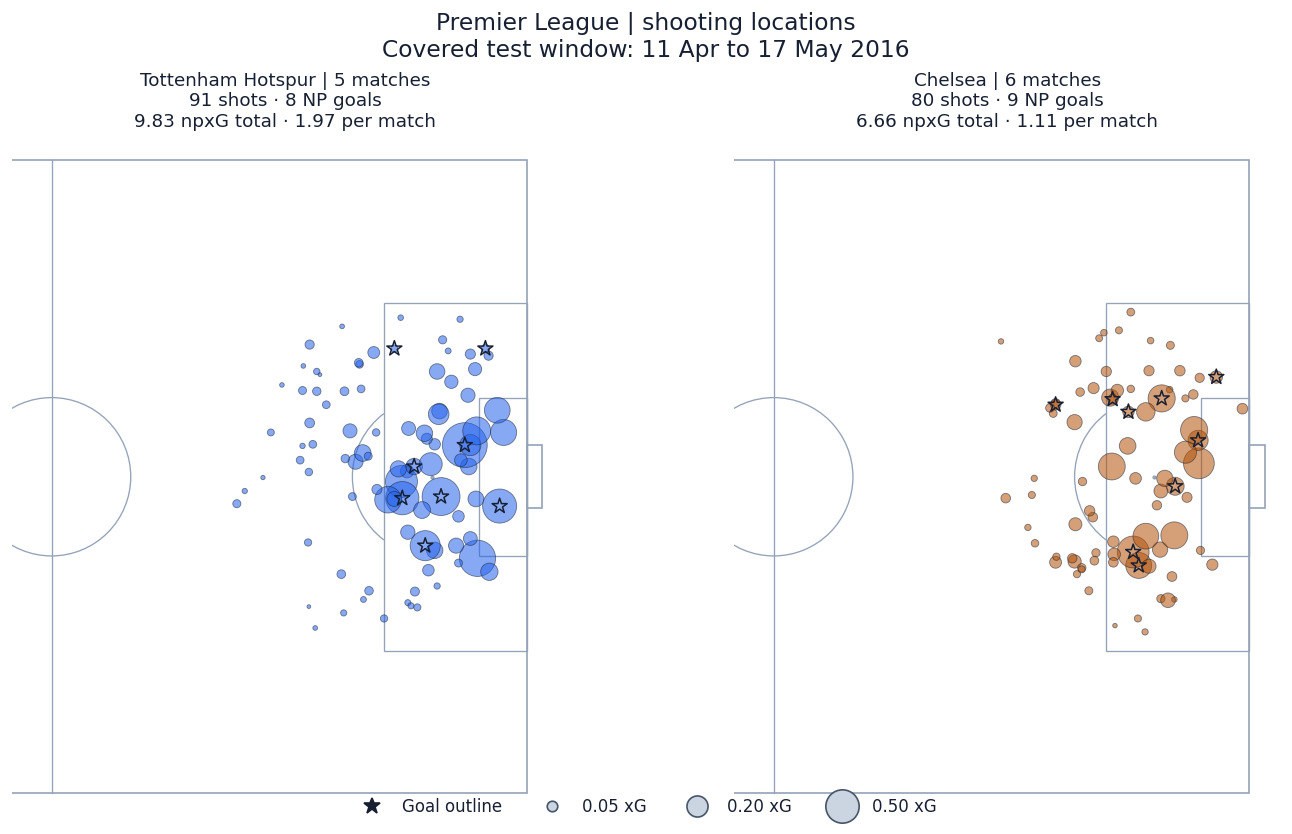

In [10]:
def draw_pitch(ax,left_bound):
    color="#94a3b8"
    ax.add_patch(Rectangle((0,0),120,80,fill=False,ec=color,lw=1))
    ax.plot([60,60],[0,80],color=color,lw=.8)
    ax.add_patch(Circle((60,40),10,fill=False,ec=color,lw=.8))
    ax.add_patch(Rectangle((102,18),18,44,fill=False,ec=color,lw=.8))
    ax.add_patch(Rectangle((114,30),6,20,fill=False,ec=color,lw=.8))
    ax.add_patch(Rectangle((120,36),2,8,fill=False,ec=color,lw=1))
    ax.add_patch(Arc((108,40),20,20,theta1=127,theta2=233,ec=color,lw=.8))
    ax.plot(108,40,".",color=color,ms=3)
    ax.set(xlim=(left_bound,124),ylim=(83,-3),aspect="equal");ax.axis("off")


def plot_shot_locations(league,teams):
    selected=selected_profiles(league,teams)
    cohort=shots.loc[shots.league.eq(league)&shots.team_name.isin(teams)]
    coords=cohort[["shot_x","shot_y"]].to_numpy(dtype=float)
    if (not np.isfinite(coords).all() or not cohort.shot_x.between(0,120).all()
            or not cohort.shot_y.between(0,80).all()):
        raise ValueError("Define an explicit policy for invalid shot coordinates before plotting this cohort.")
    left_bound=min(55.,float(cohort.shot_x.min())-5) if len(cohort) else 55.
    fig,axes=plt.subplots(1,len(teams),figsize=(6*len(teams),6.8),layout="constrained",squeeze=False)
    for i,(ax,team) in enumerate(zip(axes.flat,teams)):
        draw_pitch(ax,left_bound)
        rows=cohort.loc[cohort.team_name.eq(team)]
        ax.scatter(rows.shot_x,rows.shot_y,s=800*rows.stack_identity,color=TEAM_COLORS[i],alpha=.55,ec="#172033",lw=.5,zorder=3)
        goals=rows.loc[rows.is_goal]
        ax.scatter(goals.shot_x,goals.shot_y,s=90,marker="*",facecolors="none",ec="#172033",lw=.9,zorder=4)
        row=selected.loc[team]
        ax.set_title(f"{team} | {int(row.matches)} matches\n{int(row.shots_for)} shots · {int(row.goals_for)} NP goals\n"
                     f"{row.npxg_for:.2f} npxG total · {row.npxg_for_per_match:.2f} per match",fontsize=11)
    handles=[Line2D([],[],ls="",marker="*",color="#172033",ms=10,label="Goal outline")]
    for probability in [.05,.20,.50]:
        handles.append(Line2D([],[],ls="",marker="o",ms=np.sqrt(800*probability),mfc="#cbd5e1",mec="#475569",label=f"{probability:.2f} xG"))
    fig.legend(handles=handles,loc="lower center",ncol=4,frameon=False,bbox_to_anchor=(.5,-.01))
    fig.suptitle(f"{league} | shooting locations\nCovered test window: {SCOPE_LABEL}",fontsize=14)
    plt.show();plt.close(fig)
    return fig

location_figure=plot_shot_locations(DEFAULT_LEAGUE,DEFAULT_TEAMS)


### 10. Match-by-match attacking and opponent xG

Keep individual matches visible rather than fitting a trend to a handful of observations. Each
panel uses the same y-axis scale. Zero-shot appearances are retained as zero attacking xG.
The match log below the figure makes opponent and venue differences inspectable.

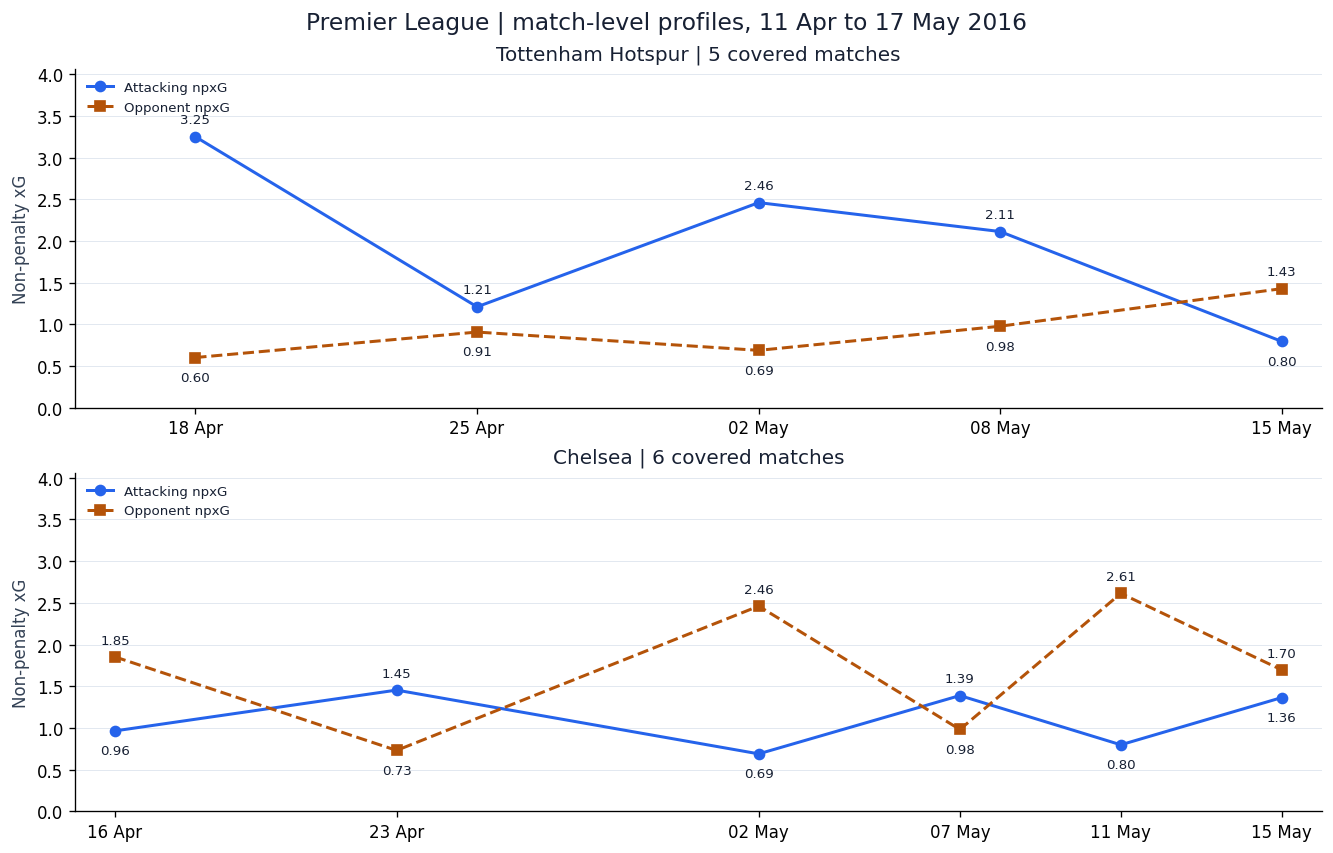

,match_date,team_name,opponent_name,venue,shots_for,shots_against,goals_for,npxg_for,npxg_against
22,2016-04-16,Chelsea,Manchester City,Home,12,11,0,0.964,1.852
165,2016-04-23,Chelsea,AFC Bournemouth,Away,16,13,4,1.454,0.730
330,2016-05-02,Chelsea,Tottenham Hotspur,Home,13,16,2,0.689,2.460
346,2016-05-07,Chelsea,Sunderland,Away,9,14,2,1.388,0.981
443,2016-05-11,Chelsea,Liverpool,Away,13,28,1,0.798,2.613
517,2016-05-15,Chelsea,Leicester City,Home,17,19,0,1.364,1.695
103,2016-04-18,Tottenham Hotspur,Stoke City,Away,22,13,4,3.250,0.603
233,2016-04-25,Tottenham Hotspur,West Bromwich Albion,Home,17,16,0,1.211,0.908
331,2016-05-02,Tottenham Hotspur,Chelsea,Away,16,13,2,2.460,0.689
399,2016-05-08,Tottenham Hotspur,Southampton,Home,19,10,1,2.114,0.978


In [11]:
def match_log(league,teams):
    selected_profiles(league,teams)
    rows=team_games.loc[team_games.league.eq(league)&team_games.team_name.isin(teams)].sort_values(["team_name","match_date","match_id"])
    return round_numeric(rows[["match_date","team_name","opponent_name","venue","shots_for","shots_against", "goals_for","npxg_for","npxg_against"]])


def plot_match_trends(league,teams):
    selected_profiles(league,teams)
    cohort=team_games.loc[team_games.league.eq(league)&team_games.team_name.isin(teams)]
    maximum=cohort[["npxg_for","npxg_against"]].to_numpy().max()*1.25
    fig,axes=plt.subplots(len(teams),1,figsize=(11,3.5*len(teams)),layout="constrained",squeeze=False)
    for ax,team in zip(axes.flat,teams):
        rows=cohort.loc[cohort.team_name.eq(team)].sort_values(["match_date","match_id"])
        for column,color,marker,linestyle,label in [
            ("npxg_for","#2563eb","o","-","Attacking npxG"),
            ("npxg_against","#b45309","s","--","Opponent npxG")]:
            ax.plot(rows.match_date,rows[column],marker=marker,ls=linestyle,color=color,label=label,lw=1.8)
            other="npxg_against" if column=="npxg_for" else "npxg_for"
            for date,value,other_value in zip(rows.match_date,rows[column],rows[other]):
                higher=value>other_value or (value==other_value and column=="npxg_for")
                offset=(22 if higher else 8) if min(value,other_value)<.06*maximum else (8 if higher else -14)
                ax.annotate(f"{value:.2f}",(date,value),xytext=(0,offset),textcoords="offset points",ha="center",fontsize=8)
        ax.set(ylim=(0,max(maximum,.1)),ylabel="Non-penalty xG",title=f"{team} | {len(rows)} covered matches")
        ax.set_xticks(rows.match_date);ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
        ax.set_xlim(cohort.match_date.min()-pd.Timedelta(days=1),cohort.match_date.max()+pd.Timedelta(days=1))
        ax.legend(loc="upper left",frameon=False,fontsize=8);ax.grid(axis="y",color="#e2e8f0",lw=.6)
    fig.suptitle(f"{league} | match-level profiles, {SCOPE_LABEL}",fontsize=14)
    plt.show();plt.close(fig)
    return fig

trend_figure=plot_match_trends(DEFAULT_LEAGUE,DEFAULT_TEAMS)
display(match_log(DEFAULT_LEAGUE,DEFAULT_TEAMS))


### 11. Live league and team selector

Choose a league and two different teams, then click **Update profiles**. Changing selections does not
refit models or request raw match events. The widget display needs a live kernel and notebook widget
support. The static examples above and the functions remain available if your host cannot display widgets.

```python
profile_table("La Liga")
plot_volume_quality("La Liga", ("Barcelona", "Real Madrid"))
```

In [12]:
def show_profiles(league,teams):
    selected_profiles(league,teams)
    display(Markdown(f"### {html.escape(league)} | {html.escape(' and '.join(teams))}\nCovered test window: {SCOPE_LABEL}."))
    display(profile_table(league)[PROFILE_COLUMNS])
    for plotting in [plot_volume_quality,plot_attack_defence,plot_patterns,plot_shot_locations,plot_match_trends]:
        plotting(league,teams)
    display(match_log(league,teams))


def build_profile_selector():
    try:
        import ipywidgets as widgets
    except ImportError:
        display(Markdown("Install `ipywidgets` to use the selector. Plotting functions and saved examples still work."))
        return None
    league=widgets.Dropdown(options=sorted(profiles.league.unique()),value=DEFAULT_LEAGUE,description="League")
    names=sorted(league_profiles(DEFAULT_LEAGUE).team_name)
    first=widgets.Dropdown(options=names,value=DEFAULT_TEAMS[0],description="Team A")
    second=widgets.Dropdown(options=names,value=DEFAULT_TEAMS[1],description="Team B")
    update=widgets.Button(description="Update profiles",button_style="primary")
    reset=widgets.Button(description="Reset")
    status=widgets.HTML(value="Choose a league and two teams, then update.")
    output=widgets.Output()

    def league_changed(_):
        choices=sorted(league_profiles(league.value).team_name)
        old_a,old_b=first.value,second.value
        first.options=second.options=choices
        first.value=old_a if old_a in choices else choices[0]
        second.value=old_b if old_b in choices and old_b!=first.value else next(name for name in choices if name!=first.value)
        status.value="Selections changed. Click Update profiles to refresh the report."

    def render(_=None):
        with output:
            output.clear_output(wait=True)
            if first.value==second.value:
                status.value="Choose two different teams."
                display(Markdown("Choose two different teams to compare."))
                return
            update.disabled=True
            try:
                show_profiles(league.value,(first.value,second.value))
                status.value="Displayed "+html.escape(league.value)+" | "+html.escape(first.value)+" and "+html.escape(second.value)
            finally:
                update.disabled=False

    def reset_selection(_):
        league.value=DEFAULT_LEAGUE
        first.value,second.value=DEFAULT_TEAMS
        render()

    league.observe(league_changed,names="value")
    update.on_click(render);reset.on_click(reset_selection)
    panel=widgets.VBox([league,widgets.HBox([first,second]),widgets.HBox([update,reset]),status,output])
    display(panel)
    return {"panel":panel,"league":league,"first":first,"second":second,"update":update,"reset":reset,"status":status,"output":output}

selector=build_profile_selector()


## Takeaways

The summaries below use the selected example teams and pooled league references. They describe
this covered window. Opponent strength, match state and sampling variation can affect the profiles;
a high xG figure alone does not establish a tactical cause or justify a fresh performance claim.

In [13]:
selected=selected_profiles(DEFAULT_LEAGUE,DEFAULT_TEAMS)
reference=league_reference(DEFAULT_LEAGUE)
for team,row in selected.iterrows():
    display(Markdown(
        f"- **{team}:** {int(row.matches)} matches, **{row.shots_for_per_match:.2f} shots per match** and "
        f"**{row.npxg_per_shot:.3f} npxG per shot**, producing **{row.npxg_for_per_match:.2f} npxG per match**. "
        f"Opponent npxG was **{row.npxg_against_per_match:.2f} per match**."
    ))
display(Markdown(f"The pooled {DEFAULT_LEAGUE} reference is **{reference['shots_per_match']:.2f} shots per team appearance** "
                 f"and **{reference['npxg_per_shot']:.3f} npxG per shot**. "
                 "These are within-league descriptive comparisons, not full-season or opponent-adjusted rankings."))


- **Tottenham Hotspur:** 5 matches, **18.20 shots per match** and **0.108 npxG per shot**, producing **1.97 npxG per match**. Opponent npxG was **0.92 per match**.

- **Chelsea:** 6 matches, **13.33 shots per match** and **0.083 npxG per shot**, producing **1.11 npxG per match**. Opponent npxG was **1.72 per match**.

The pooled Premier League reference is **13.61 shots per team appearance** and **0.097 npxG per shot**. These are within-league descriptive comparisons, not full-season or opponent-adjusted rankings.

### Checks and source receipt

The checks reconcile both sides of every match, shot totals, goals and probabilities. They also
confirm that profile rates are ratios of totals. Original training, model and evaluation artifacts are
only read. Test results must not be used for new tuning described as independently validated.

Sources: [StatsBomb Open Data](https://github.com/hudl/open-data), pinned to
`3bfbffe1de5750ebd47d770be0bb924a10cde54f`, and the project's original frozen predictions,
stage-8 features and match metadata. Credit StatsBomb when sharing derived work.

In [14]:
assert len(team_games)==2*len(fixtures)
assert len(profiles)==shots.team_id.nunique()==98
assert team_games.shots_for.sum()==team_games.shots_against.sum()==len(shots)
assert team_games.goals_for.sum()==team_games.goals_against.sum()==int(shots.is_goal.sum())
np.testing.assert_allclose([team_games.npxg_for.sum(),team_games.npxg_against.sum(),profiles.npxg_for.sum()],shots.stack_identity.sum(),rtol=0,atol=1e-10)
np.testing.assert_allclose((profiles.npxg_for_per_match*profiles.matches).sum(),shots.stack_identity.sum(),rtol=0,atol=1e-10)
recorded_total=next(row["expected_goals"] for row in result["calibration_totals"] if row["model"]=="stack_identity")
np.testing.assert_allclose(profiles.npxg_for.sum(),recorded_total,rtol=0,atol=1e-9)
assert profiles.matches.sum()==2*len(fixtures)
assert not profiles.duplicated(["league","team_id"]).any()
assert pattern_summary(DEFAULT_LEAGUE,DEFAULT_TEAMS).share.between(0,1).all()
source_receipt={
    "data_source":manifest["data_source"],"prediction_file":prediction_relative,
    "prediction_sha256":result["artifact_sha256"][prediction_relative],
    "feature_file":FEATURE_RELATIVE,"feature_sha256":manifest["files"][FEATURE_RELATIVE]["sha256"],
    "match_catalogues":catalogue_sources,"first_match":str(SCOPE_START.date()),"last_match":str(SCOPE_END.date()),
    "shots":len(shots),"fixtures":len(fixtures),"team_appearances":len(team_games),"teams":len(profiles),
    "denominator":"both sides of all covered matches, including zero-shot appearances",
    "eligibility":"non-penalty shots only","prediction_source":"original frozen test forecasts",
}
print("Checks passed: frozen inputs, authoritative team IDs, fixture exposure, same-match opponents and all aggregate totals.")
print(f"Coverage: {len(profiles)} teams; {profiles.matches.min()} to {profiles.matches.max()} matches per team.")


Checks passed: frozen inputs, authoritative team IDs, fixture exposure, same-match opponents and all aggregate totals.
Coverage: 98 teams; 4 to 7 matches per team.
